⏳ Fetching Ghana region boundaries...
✅ Loaded 10 regions: Upper East, Northern, Volta, Brong Ahafo, Western, Upper West, Central, Greater Accra, Ashanti, Eastern


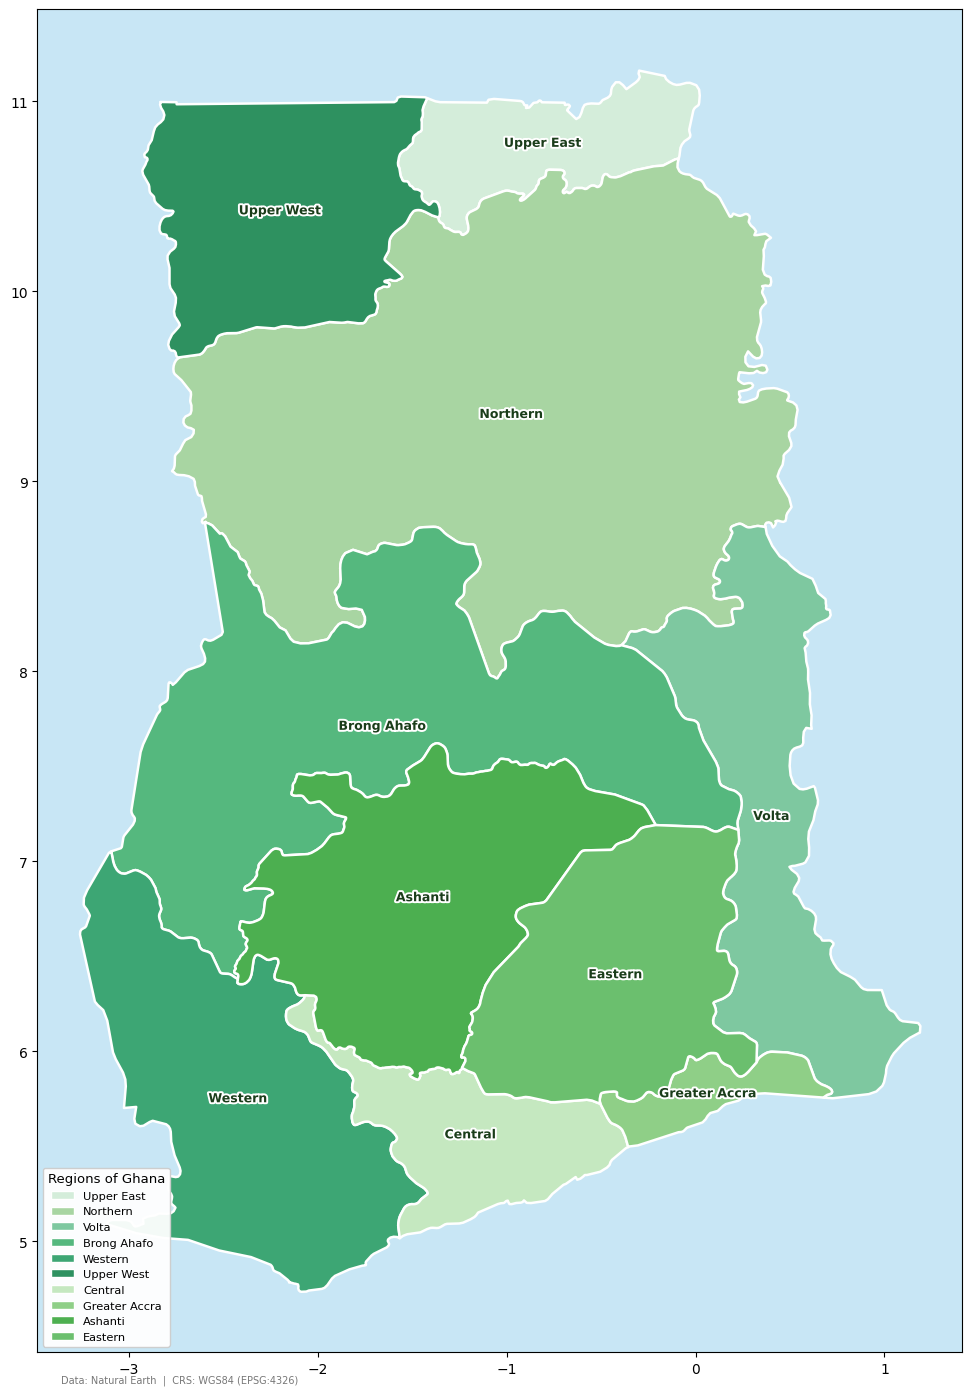


✅ Map saved as 'ghana_regions_map.png'
   Download it from the Colab Files panel (folder icon on the left).


In [2]:

# Step 1: Install dependencies
import subprocess
subprocess.run(["pip", "install", "geopandas", "matplotlib", "shapely", "requests", "--quiet"])

import requests
import json
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import warnings
warnings.filterwarnings("ignore")

# Step 2: Load Ghana regions from Natural Earth (via GitHub)
print("⏳ Fetching Ghana region boundaries...")

url = (
    "https://raw.githubusercontent.com/nvkelso/natural-earth-vector"
    "/master/geojson/ne_10m_admin_1_states_provinces.geojson"
)
r = requests.get(url, timeout=60)
r.raise_for_status()

all_features = r.json()["features"]
ghana_features = [
    f for f in all_features
    if f["properties"].get("admin") == "Ghana"
]

ghana_gdf = gpd.GeoDataFrame.from_features(ghana_features, crs="EPSG:4326")
print(f"✅ Loaded {len(ghana_gdf)} regions: {', '.join(ghana_gdf['name'].tolist())}")

# Step 3: Assign distinct green shades (one per region)
# 10 carefully chosen greens — light to dark, all clearly distinct
green_palette = [
    "#d4edda",   # very light mint       — Upper East
    "#a8d5a2",   # soft sage green       — Northern
    "#7ec8a0",   # medium seafoam        — Volta
    "#55b87e",   # fresh mid-green       — Brong Ahafo
    "#3da674",   # medium-dark green     — Western
    "#2e9160",   # rich forest green     — Upper West
    "#c5e8c0",   # pale cucumber         — Central
    "#8fcf87",   # bright apple green    — Greater Accra
    "#4caf50",   # classic vivid green   — Ashanti
    "#6bbf6e",   # warm leafy green      — Eastern
]

# Map colours to regions in the order they appear
ghana_gdf["color"] = green_palette[: len(ghana_gdf)]


# ============================================================
# Step 5: Draw the map
# ============================================================
fig, ax = plt.subplots(1, 1, figsize=(11, 14))
ax.set_facecolor("#c8e6f5")   # light-blue ocean / background

# --- Plot each region individually so colours stay correct ---
for _, row in ghana_gdf.iterrows():
    gpd.GeoDataFrame([row], crs="EPSG:4326").plot(
        ax=ax,
        color=row["color"],
        edgecolor="white",
        linewidth=1.8,
        zorder=2,
    )

# --- Region name labels ---
for _, row in ghana_gdf.iterrows():
    cx = row.geometry.centroid.x
    cy = row.geometry.centroid.y
    ax.text(
        cx, cy, row["name"],
        fontsize=9, ha="center", va="center",
        fontweight="bold", color="#1a3d1a", zorder=5,
        path_effects=[pe.withStroke(linewidth=2.8, foreground="white")],
    )


# ============================================================
# Step 7: Legend
# ============================================================
legend_elements = [
    mpatches.Patch(
        facecolor=ghana_gdf.iloc[i]["color"],
        edgecolor="white",
        label=ghana_gdf.iloc[i]["name"],
    )
    for i in range(len(ghana_gdf))
]


ax.legend(
    handles=legend_elements,
    loc="lower left",
    fontsize=8.2,
    framealpha=0.95,
    edgecolor="#cccccc",
    title="Regions of Ghana",
    title_fontsize=9.5,
)

# --- North arrow ---
ax.annotate(
    "N",
    xy=(maxx + 0.35, maxy + 0.35),
    fontsize=15, fontweight="bold", ha="center", color="#1a3d1a",
)
ax.annotate(
    "",
    xy=(maxx + 0.35, maxy + 0.6),
    xytext=(maxx + 0.35, maxy + 0.1),
    arrowprops=dict(arrowstyle="->", color="#1a3d1a", lw=2.2),
)

# --- Data credit ---
ax.text(
    minx - 0.1, miny - 0.48,
    "Data: Natural Earth  |  CRS: WGS84 (EPSG:4326)",
    fontsize=7, color="#777777",
)

plt.tight_layout()

# ============================================================
# Step 8: Save PNG
# ============================================================
output = "ghana_regions_map.png"
plt.savefig(output, dpi=200, bbox_inches="tight",
            facecolor="#c8e6f5", edgecolor="none")
plt.show()
print(f"\n✅ Map saved as '{output}'")
print("   Download it from the Colab Files panel (folder icon on the left).")